In [4]:
%pip install -q -U ultralytics roboflow python-dotenv


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 95.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.2 MB/s eta 0:00:00


In [7]:
from roboflow import Roboflow
from ultralytics import YOLO
from getpass import getpass
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

api_key = getpass(
    "Pega la API key de Roboflow que compartió el profesor: "
).strip()

if not api_key:
    raise ValueError("Debes ingresar la API key de Roboflow.")

Pega la API key de Roboflow que compartió el profesor: ··········


In [8]:
rf = Roboflow(api_key=api_key)

project = rf.workspace("roboflow-jvuqo").project(
    "football-players-detection-3zvbc"
)

dataset = project.version(1).download("yolo26")

print(f"Dataset descargado en: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-players-detection-1 in yolo26:: 100%|██████████| 1338/1338 [00:03<00:00, 387.79it/s]

Dataset descargado en: /content/football-players-detection-1


In [9]:
model = YOLO("yolo26n.pt")

results = model.train(
    data=str(Path(dataset.location) / "data.yaml"),
    epochs=20,
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/football-players-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optim

In [10]:
# Recuperar el modelo con mejor resultado de validación.
best_weights = Path(model.trainer.save_dir) / "weights" / "best.pt"

if not best_weights.exists():
    raise FileNotFoundError(
        f"No se encontraron los pesos entrenados: {best_weights}"
    )

model = YOLO(str(best_weights))

# Seleccionar una imagen del conjunto de prueba.
test_dir = Path(dataset.location) / "test" / "images"

test_images = sorted(
    path
    for path in test_dir.glob("*")
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

if not test_images:
    raise FileNotFoundError(
        f"No se encontraron imágenes de prueba en: {test_dir}"
    )

image_path = str(test_images[0])

print(f"Usando imagen de prueba: {image_path}")

resultados = model(
    image_path,
    conf=0.25,
)

Usando imagen de prueba: /content/football-players-detection-1/test/images/40cd38_7_6_png.rf.68ef7fcd663cdf0f5b96bacdbcd94e07.jpg

image 1/1 /content/football-players-detection-1/test/images/40cd38_7_6_png.rf.68ef7fcd663cdf0f5b96bacdbcd94e07.jpg: 384x640 23 players, 9.7ms
Speed: 1.8ms preprocess, 9.7ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)


In [11]:
r = resultados[0]

print("=== Información general ===")
print(f"Imagen original: {r.path}")
print(f"Tamaño original (alto, ancho): {r.orig_shape}")
print(f"Objetos detectados: {len(r.boxes)}")

print("\n=== Detecciones ===")

for i, box in enumerate(r.boxes):
    clase_id = int(box.cls[0])
    clase_nombre = r.names[clase_id]
    confianza = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(
        f"[{i + 1}] {clase_nombre} | "
        f"confianza: {confianza:.2f} | "
        f"bbox: ({x1:.0f}, {y1:.0f}) → ({x2:.0f}, {y2:.0f})"
    )

=== Información general ===
Imagen original: /content/football-players-detection-1/test/images/40cd38_7_6_png.rf.68ef7fcd663cdf0f5b96bacdbcd94e07.jpg
Tamaño original (alto, ancho): (1080, 1920)
Objetos detectados: 23

=== Detecciones ===
[1] player | confianza: 0.88 | bbox: (1856, 754) → (1894, 830)
[2] player | confianza: 0.87 | bbox: (1319, 598) → (1355, 658)
[3] player | confianza: 0.84 | bbox: (644, 545) → (664, 593)
[4] player | confianza: 0.83 | bbox: (798, 617) → (820, 682)
[5] player | confianza: 0.83 | bbox: (1081, 788) → (1118, 871)
[6] player | confianza: 0.83 | bbox: (1279, 540) → (1299, 588)
[7] player | confianza: 0.82 | bbox: (1746, 674) → (1785, 746)
[8] player | confianza: 0.82 | bbox: (1819, 626) → (1847, 689)
[9] player | confianza: 0.81 | bbox: (1683, 614) → (1719, 679)
[10] player | confianza: 0.80 | bbox: (545, 672) → (595, 747)
[11] player | confianza: 0.79 | bbox: (906, 518) → (928, 571)
[12] player | confianza: 0.78 | bbox: (816, 482) → (839, 523)
[13] player |

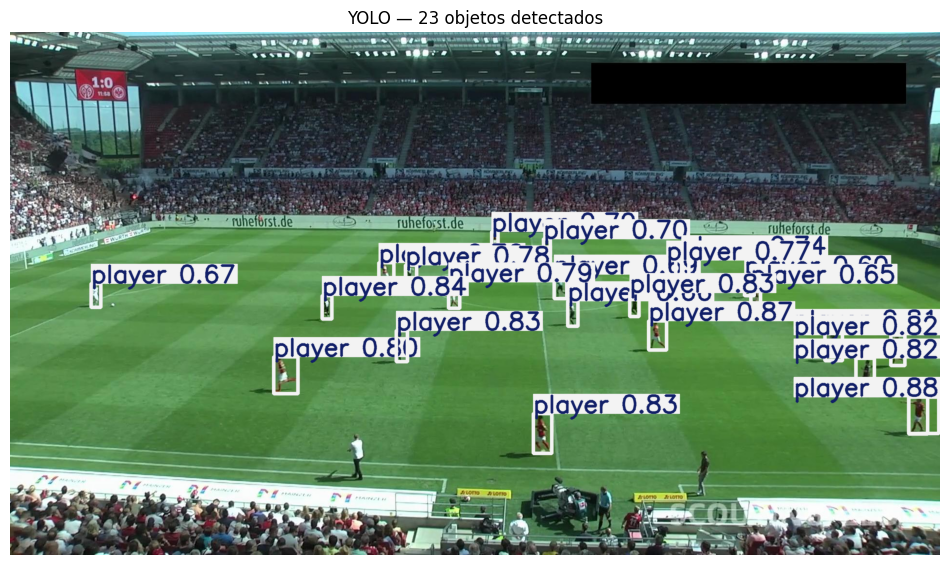

In [12]:
imagen_anotada = r.plot()

# Convertir BGR a RGB para mostrar los colores correctamente.
imagen_anotada_rgb = imagen_anotada[:, :, ::-1]

plt.figure(figsize=(12, 7))
plt.imshow(imagen_anotada_rgb)
plt.title(f"YOLO — {len(r.boxes)} objetos detectados")
plt.axis("off")
plt.show()